In [1]:
import logging

logging.basicConfig(level=logging.INFO, force=True)


from networkx.drawing import (
    draw as nx_draw,
    spring_layout,
)
from networkx import get_node_attributes, connected_components
from networkx.generators import path_graph

from mupt.trees.subselect import NodePredicate
from mupt.mupr.primitives import (
    Primitive,
    CompositePrimitive,
)
from mupt.mupr.properties import is_subdominant

from mupt.interfaces.smiles import primitive_from_smiles
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

INFO:rdkit:Enabling RDKit 2026.09.1 jupyter extensions
INFO:freud.msd:Using SciPy's fftpack for FFTs


# PAAm homopolymer

## Assemble MuPT repr

In [2]:
DOP: int = 10
lexicon = {
    "head": primitive_from_smiles(
        "[H:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]", label="_A"
    ),
    "mid": primitive_from_smiles(
        "[*:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]", label="_B"
    ),
    "tail": primitive_from_smiles(
        "[*:1]-[C:2]CC(=O)[N:1](-[H])-[H:2]", label="_C"
    ),
}

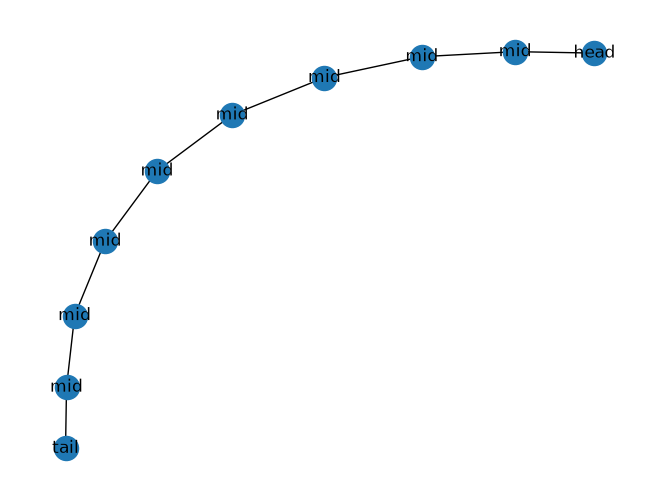

In [3]:
sequence = ["head"] + (DOP - 2) * ["mid"] + ["tail"]
sequence_graph = path_graph(len(sequence))
for i, label in enumerate(sequence):
    sequence_graph.nodes[i]["label"] = label

nx_draw(
    sequence_graph,
    with_labels=True,
    labels=get_node_attributes(sequence_graph, "label"),
)

### Select, connect, then inspect

In [4]:
# predicate : NodePredicate[Primitive] = lambda prim: isinstance(prim, CompositePrimitive)
# predicate : NodePredicate[Primitive] = lambda prim : is_atom(prim) and prim.element.symbol != 'H'
predicate: NodePredicate[Primitive] = is_subdominant

In [5]:
molprim = CompositePrimitive()
molprim.populate_from_topology_and_lexicon(
    sequence_graph, lexicon, label_attr="label"
)
xsec = molprim.cross_section(predicate)

print(f"{len(list(connected_components(xsec)))} molecules")

INFO:mupt.mupr.connection.linking:Paired up 9 new edges after 1 iteration(s); 0/9 edges remain unpaired
INFO:mupt.mupr.connection.linking:Linking protocol successful! 9/9 edges were assigned Connector pairings


1 molecules


<Axes: >

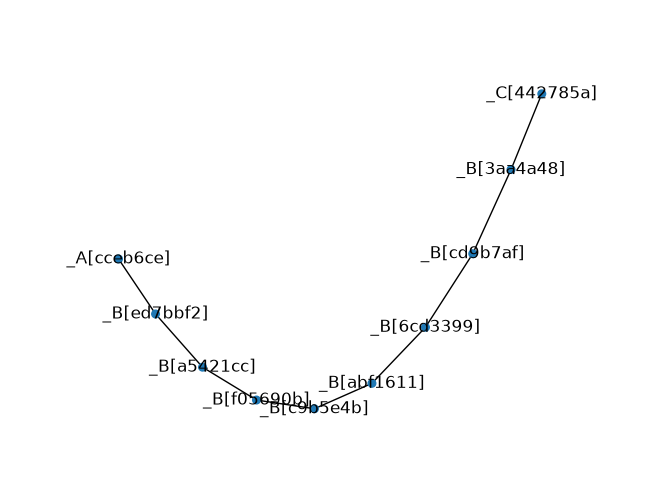

In [6]:
pos = spring_layout(xsec, dim=2)
molprim.visualize_cross_section(xsec, pos=pos, with_labels=True, node_size=30)

## Export to mbuild

In [7]:
compound = primitive_to_mbuild(molprim, predicate=predicate)
...  # insert downstream code here
print(compound)

<COMPOSITE 10 particles, 9 bonds, non-periodic, id: 10831471888>


In [8]:
compound.bonds()

EdgeView([(<_A pos=([0. 0. 0.]), 1 bonds, id: 10835591248>, <_B pos=([0. 0. 0.]), 2 bonds, id: 10835591568>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 10835591568>, <_B pos=([0. 0. 0.]), 2 bonds, id: 10831523488>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 10831523488>, <_B pos=([0. 0. 0.]), 2 bonds, id: 10831524096>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 10831524096>, <_B pos=([0. 0. 0.]), 2 bonds, id: 10835478000>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 10835478000>, <_B pos=([0. 0. 0.]), 2 bonds, id: 10831394704>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 10831394704>, <_B pos=([0. 0. 0.]), 2 bonds, id: 10831394976>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 10831394976>, <_B pos=([0. 0. 0.]), 2 bonds, id: 10833861968>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 10833861968>, <_B pos=([0. 0. 0.]), 2 bonds, id: 10833861712>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 10833861712>, <_C pos=([0. 0. 0.]), 1 bonds, id: 10834088480>)])

In [9]:
compound.children

[<_A pos=([0. 0. 0.]), 1 bonds, id: 10835591248>,
 <_B pos=([0. 0. 0.]), 2 bonds, id: 10835591568>,
 <_B pos=([0. 0. 0.]), 2 bonds, id: 10831523488>,
 <_B pos=([0. 0. 0.]), 2 bonds, id: 10831524096>,
 <_B pos=([0. 0. 0.]), 2 bonds, id: 10835478000>,
 <_B pos=([0. 0. 0.]), 2 bonds, id: 10831394704>,
 <_B pos=([0. 0. 0.]), 2 bonds, id: 10831394976>,
 <_B pos=([0. 0. 0.]), 2 bonds, id: 10833861968>,
 <_B pos=([0. 0. 0.]), 2 bonds, id: 10833861712>,
 <_C pos=([0. 0. 0.]), 1 bonds, id: 10834088480>]

In [10]:
compound.bond_graph

In [11]:
import warnings

warnings.filterwarnings("ignore")
from flowermd.base import Molecule

molecules = Molecule(
    num_mols=1, compound=compound, name="PAMAM", identify_connections=False
)

INFO:numexpr.utils:NumExpr defaulting to 11 threads.


In [12]:
molecules

In [13]:
molecules.bond_types

{('_A', '_B'), ('_B', '_B'), ('_B', '_C')}

In [14]:
from flowermd.library import RandomWalk
import unyt as u

ref_length = 1.0 * u.Unit("nm")
ref_mass = 1.0 * u.Unit("g/mol")
ref_energy = 1.0 * u.Unit("kcal / mol")
ref_values_dict = {"length": ref_length, "mass": ref_mass, "energy": ref_energy}

system = RandomWalk(
    molecules=molecules,
    density=0.8 * u.Unit("nm**-3"),
    bond_length=1.0,
    base_units=ref_values_dict,
    seed=456,
)
system.box

Box: Lx=2.320794, Ly=2.320794, Lz=2.320794, xy=0.000000, xz=0.000000, yz=0.000000, 

In [15]:
system.all_molecules[0].children

[<_A pos=([-0.0704 -0.1215 -0.8725]), 1 bonds, id: 10916022416>,
 <_B pos=([-0.0605 -0.4456  0.0735]), 2 bonds, id: 10916022608>,
 <_B pos=([ 0.7373  0.013  -0.3179]), 2 bonds, id: 10916022800>,
 <_B pos=([ 1.017  -0.9265 -0.5157]), 2 bonds, id: 10916022992>,
 <_B pos=([-0.4587 -1.0193 -1.0423]), 2 bonds, id: 10916023184>,
 <_B pos=([ 0.9277  0.9493 -0.9892]), 2 bonds, id: 10916023376>,
 <_B pos=([ 0.5658 -0.5948  0.8159]), 2 bonds, id: 10916023568>,
 <_B pos=([-0.3386 -0.873   0.4925]), 2 bonds, id: 10916023760>,
 <_B pos=([0.001  0.5472 0.2212]), 2 bonds, id: 10916023952>,
 <_C pos=([ 0.3723 -1.0295  0.7766]), 1 bonds, id: 10916024144>]

In [16]:
from flowermd.library import (
    Bead_Spring_DPD,
)  # check which xml your environment is pointing at
import hoomd

nlist = hoomd.md.nlist.Cell(buffer=0.1, exclusions=["bond"])
system.apply_forcefield(
    force_field=Bead_Spring_DPD(), kT=1.0, r_cut=1.01, nlist=nlist
)

In [17]:
from flowermd.library import PhantomWalk
import hoomd

sim = PhantomWalk(
    initial_state=system.hoomd_snapshot,
    forcefield=system.hoomd_forcefield,
    gsd_write_freq=100,
    log_write_freq=50,
    n_steps_dpd=500,
    n_steps_fire=100,
    write_at_start=True,
)

for writer in sim.operations.writers:
    if isinstance(writer, hoomd.write.GSD):
        writer.flush()

Initializing simulation state from a gsd.hoomd.Frame.
Step 75 of 500; TPS: 640.99; ETA: 0.0 minutes
Step 150 of 500; TPS: 1278.03; ETA: 0.0 minutes
Step 225 of 500; TPS: 1912.94; ETA: 0.0 minutes
Step 300 of 500; TPS: 2544.9; ETA: 0.0 minutes
Step 375 of 500; TPS: 3176.19; ETA: 0.0 minutes
Step 450 of 500; TPS: 3802.02; ETA: 0.0 minutes
Step 25 of 100; TPS: 1250000.0; ETA: 0.0 minutes
The closest particles after DPD + FIRE are:  1.002750039100647


INFO:gsd.fl:opening file: trajectory.gsd with mode: r
INFO:gsd.hoomd:opening HOOMDTrajectory: <gsd.fl.GSDFile object at 0x28bc1c8f0>
INFO:gsd.hoomd:found 7 frames
INFO:gsd.fl:closing file: trajectory.gsd
INFO:gsd.fl:opening file: trajectory.gsd with mode: r
INFO:gsd.hoomd:opening HOOMDTrajectory: <gsd.fl.GSDFile object at 0x133eb8930>
INFO:gsd.hoomd:found 7 frames
INFO:gsd.fl:closing file: trajectory.gsd


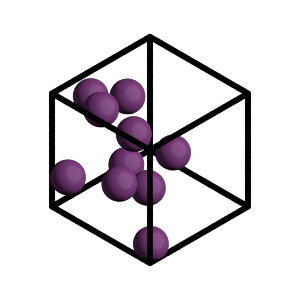

In [18]:
from cmeutils.visualize import FresnelGSD

sim_visualizer = FresnelGSD(
    gsd_file="trajectory.gsd", frame=0, view_axis=(1, 1, 1)
)
sim_visualizer.view()

INFO:gsd.fl:opening file: trajectory.gsd with mode: r
INFO:gsd.hoomd:opening HOOMDTrajectory: <gsd.fl.GSDFile object at 0x28bc2d5b0>
INFO:gsd.hoomd:found 7 frames
INFO:gsd.fl:closing file: trajectory.gsd


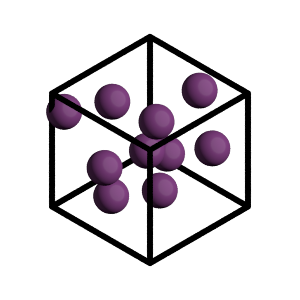

In [19]:
sim_visualizer.frame = -1
sim_visualizer.view()